## **XG Boost** ##
The aim for introducing Random Forest (Regressor) to the project is to **predict future number of influenza case detections** with the obtained data. The difference with it and Random FOrest is that XGBoost construct the next tree based on the performance of the previous tree. It is not primarily chosen because of its higher complexity and longer execution time comparing to Random Forest. However, we would want to see whether there will be a large improvement on the prediction result with the implementation of XGBoost to decide which model should we select at last. 

---

In [1]:
import pandas as pd 
import numpy as np

from scipy.stats import randint, uniform
from xgboost import XGBRegressor
import xgboost as xgbl
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

import graphviz
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data_engineed.csv")
df["From"] = pd.to_datetime(df["From"])
df = df.sort_values("From").reset_index(drop=True)

In [3]:
mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
flu_col = ["H1", "H3", "B", "AandB"]

---

**Grid of hyperparameters**
1. `n_estimators`: The number of tress in the forest
2. `learning_rate`: Learning rate / Step size
3. `max_depth`: The maximum depth of each tree
4. `subsample`: 
5. `colsample_bytree`: 
6. `min_child_weight`: 
7. `reg_alpha`: $\alpha$ for regularization
8. `reg_lambda`: $\lambda$ for regularization

In [4]:
grid = {
    "n_estimators": [x for x in range(100, 1000, 100)],
    "learning_rate": uniform(0.01, 0.20), 
    "max_depth": [x for x in range(3, 9)], 
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(10, 30),
    "reg_alpha": uniform(0, 5), 
    "reg_lambda": uniform(1, 10)
}

In [11]:
for col in flu_col: 
    tmp_df = df.copy()

    for n in range(3):
        tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
    tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
    tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()

    tmp_df = tmp_df.dropna().reset_index(drop=True)

    X = tmp_df.drop(columns=["From"]+flu_col)


    print(f"{'='*70} {col} {'='*70}")
    y = tmp_df[col]

    train_end = int(tmp_df.shape[0] * 0.8)
    X_train, X_test = X.iloc[:train_end], X.iloc[train_end:]
    y_train, y_test = y.iloc[:train_end], y.iloc[train_end:]

    y_train_log = np.log1p(y_train)

    tscv = TimeSeriesSplit(n_splits=5)
    xgb = XGBRegressor(random_state=42)
    xgb_cv = RandomizedSearchCV(estimator=xgb, param_distributions=grid, cv=tscv, n_jobs=-1, scoring="neg_root_mean_squared_error")

    xgb_cv.fit(X_train, y_train_log)

    print(f"Best Parameters: {xgb_cv.best_params_}")
    print("Best CV Score:", xgb_cv.best_score_)

    print(f"\nFeature importances: ")
    model = xgb_cv.best_estimator_
    importance = pd.Series(model.feature_importances_, index=X.columns)
    print(importance.sort_values(ascending=False))

    model.fit(X_train, y_train_log)
    
    # Evaluation
    y_pred_log = model.predict(X_train)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with train data: ")
    print(f"MAE: {mean_absolute_error(y_train, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_train, y_pred):.4f}")
    print(f"R2:  {r2_score(y_train, y_pred):.4f}")

    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with test data: ")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print(f"R2:  {r2_score(y_test, y_pred):.4f}")
    

====================================================================== H1 ======================================================================
Best Parameters: {'colsample_bytree': np.float64(0.991179680256046), 'learning_rate': np.float64(0.11676959948753517), 'max_depth': 7, 'min_child_weight': 10, 'n_estimators': 400, 'reg_alpha': np.float64(0.05300514298511361), 'reg_lambda': np.float64(4.302268248321093), 'subsample': np.float64(0.8099039847155352)}
Best CV Score: -0.8670924638495945

Feature importances: 
H1_Lag1                           0.641950
H1_rolling_mean                   0.228393
H1_Lag2                           0.044712
H1_volatility                     0.007760
Week                              0.007349
ContainmentHealthIndex_Average    0.007341
H1_Lag3                           0.007124
Mean temperature (°C)             0.006215
Year                              0.006122
Dew point temperature (°C)        0.005714
Air pressure (hPa)                0.005427
Diurnal 

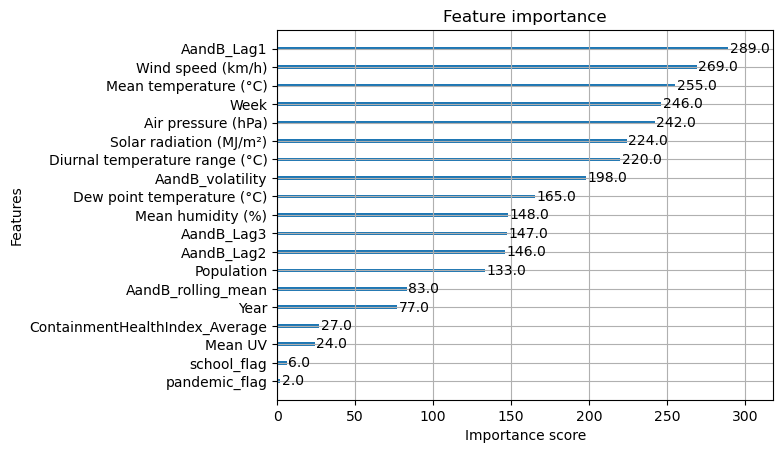

In [6]:
xgbl.plot_importance(model)
plt.show()

In [13]:
# xgbl.plot_tree(model, num_tree=2)

---
**Interpretation**